In [44]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

plt.style.use("ggplot")
sns.set_style("whitegrid")

plt.rcParams["figure.figsize"] = (10,6)

pd.set_option("display.max_columns", None)

In [45]:
# ==========================================================
# Load Datasets
# ==========================================================

transaction_df = pd.read_csv("../data/processed/merged_clean_dataset.csv")
monthly_df = pd.read_csv("../data/processed/monthly_sku_level_dataset.csv")

transaction_df["Date"] = pd.to_datetime(transaction_df["Date"])

print("Transaction Dataset :", transaction_df.shape)
print("Monthly Dataset     :", monthly_df.shape)

Transaction Dataset : (128975, 31)
Monthly Dataset     : (16486, 10)


In [46]:
transaction_df.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,ASIN,Courier Status,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Month,is_cancelled,SKU Code,Design No.,Stock,Category_stock,Size_stock,Color
0,0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,SET,S,B09KXVBD7Z,NaN,0,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,2022-04,True,SET389-KR-NP-S,SET389,32.0,SET,S,White
1,1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,KURTA,3XL,B09K3WFS32,Shipped,1,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,2022-04,False,JNE3781-KR-XXXL,JNE3781,96.0,KURTA,XXXL,Green
2,2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,KURTA,XL,B07WV4JV4D,Shipped,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,2022-04,False,JNE3371-KR-XL,JNE3371,4.0,KURTA,XL,Light Green
3,3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,WESTERN DRESS,L,B099NRCT7B,NaN,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,2022-04,True,J0341-DR-L,J0341,193.0,DRESS,L,Blue
4,4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,TOP,3XL,B098714BZP,Shipped,1,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,2022-04,False,JNE3671-TU-XXXL,JNE3671,6.0,TUNIC,XXXL,Pink


In [47]:
monthly_df.head()

,SKU,Category,Month,units_sold,gross_sales_amount,num_orders,cancelled_orders,ending_stock_snapshot,ship_state_mode,beginning_stock
0,AN201-RED-M,BOTTOM,2022-04,1,229.0,1,0,5.0,ANDHRA PRADESH,6.0
1,AN201-RED-M,BOTTOM,2022-05,1,229.0,1,0,5.0,WEST BENGAL,6.0
2,AN201-RED-XL,BOTTOM,2022-06,2,602.0,2,0,6.0,TELANGANA,8.0
3,AN201-RED-XXL,BOTTOM,2022-05,1,229.0,1,0,3.0,WEST BENGAL,4.0
4,AN202-ORANGE-M,BOTTOM,2022-04,1,229.0,1,0,3.0,TAMIL NADU,4.0


In [48]:
print(transaction_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 31 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   index               128975 non-null  int64         
 1   Order ID            128975 non-null  str           
 2   Date                128975 non-null  datetime64[us]
 3   Status              128975 non-null  str           
 4   Fulfilment          128975 non-null  str           
 5   Sales Channel       128975 non-null  str           
 6   ship-service-level  128975 non-null  str           
 7   Style               128975 non-null  str           
 8   SKU                 128975 non-null  str           
 9   Category            128975 non-null  str           
 10  Size                128975 non-null  str           
 11  ASIN                128975 non-null  str           
 12  Courier Status      122103 non-null  str           
 13  Qty                 128975 non-null  int

In [49]:
print(monthly_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 16486 entries, 0 to 16485
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SKU                    16486 non-null  str    
 1   Category               16486 non-null  str    
 2   Month                  16486 non-null  str    
 3   units_sold             16486 non-null  int64  
 4   gross_sales_amount     16486 non-null  float64
 5   num_orders             16486 non-null  int64  
 6   cancelled_orders       16486 non-null  int64  
 7   ending_stock_snapshot  15303 non-null  float64
 8   ship_state_mode        16486 non-null  str    
 9   beginning_stock        15303 non-null  float64
dtypes: float64(3), int64(3), str(4)
memory usage: 1.3 MB
None


In [50]:
transaction_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
index,128975.0,NaN,NaN,NaN,64487.0,0.0,32243.5,64487.0,96730.5,128974.0,37232.019822
Order ID,128975,120378,403-4984515-8861958,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,128975,NaN,NaN,NaN,2022-05-12 11:49:27.951929,2022-03-31 00:00:00,2022-04-20 00:00:00,2022-05-10 00:00:00,2022-06-04 00:00:00,2022-06-29 00:00:00,NaN
Status,128975,13,Shipped,77804,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfilment,128975,2,Amazon,89698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales Channel,128975,2,Amazon.in,128851,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship-service-level,128975,2,Expedited,88615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Style,128975,1377,JNE3797,4224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SKU,128975,7195,JNE3797-KR-L,773,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,128975,9,SET,50284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


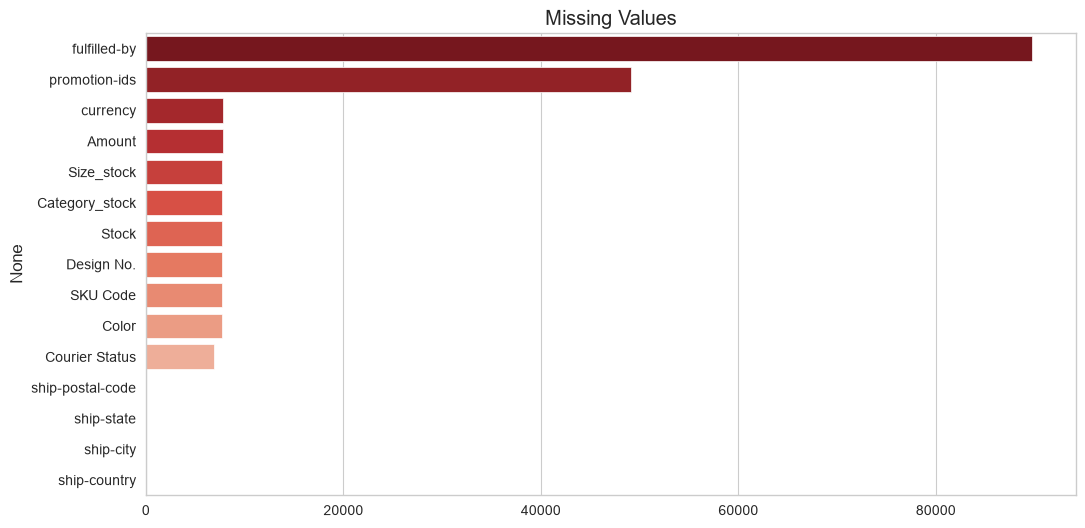

In [51]:
missing = (
    transaction_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing = missing[missing > 0]

plt.figure(figsize=(12,6))

sns.barplot(
    x=missing.values,
    y=missing.index,
    palette="Reds_r"
)

plt.title("Missing Values")

plt.show()

In [52]:
missing_percent = (
    transaction_df.isnull().mean()*100
)

missing_percent = missing_percent.sort_values(ascending=False)

missing_percent

fulfilled-by          69.546811
promotion-ids         38.110487
currency               6.043807
Amount                 6.043807
Size_stock             5.974801
Category_stock         5.974801
Stock                  5.974801
Design No.             5.974801
SKU Code               5.974801
Color                  5.974801
Courier Status         5.328164
ship-postal-code       0.025586
ship-state             0.025586
ship-city              0.025586
ship-country           0.025586
Qty                    0.000000
ASIN                   0.000000
Category               0.000000
Size                   0.000000
SKU                    0.000000
Style                  0.000000
Sales Channel          0.000000
ship-service-level     0.000000
Date                   0.000000
Order ID               0.000000
Fulfilment             0.000000
Status                 0.000000
index                  0.000000
B2B                    0.000000
Month                  0.000000
is_cancelled           0.000000
dtype: f

In [53]:
duplicates = transaction_df.duplicated().sum()

print("Duplicate Rows :",duplicates)

Duplicate Rows : 0


In [54]:
unique = pd.DataFrame({
    "Unique":transaction_df.nunique()
})

unique.sort_values("Unique",ascending=False)

,Unique
index,128975
Order ID,120378
ship-postal-code,9459
ship-city,8955
SKU,7195
ASIN,7190
SKU Code,6617
promotion-ids,5787
Amount,1410
Style,1377


In [55]:
transaction_df.describe()

,index,Date,Qty,Amount,ship-postal-code,Stock
count,128975.000000,128975,128975.000000,121180.000000,128942.000000,121269.000000
mean,64487.000000,2022-05-12 11:49:27.951929,0.904431,648.561465,463966.236509,68.516496
min,0.000000,2022-03-31 00:00:00,0.000000,0.000000,110001.000000,0.000000
25%,32243.500000,2022-04-20 00:00:00,1.000000,449.000000,382421.000000,5.000000
50%,64487.000000,2022-05-10 00:00:00,1.000000,605.000000,500033.000000,14.000000
75%,96730.500000,2022-06-04 00:00:00,1.000000,788.000000,600024.000000,67.000000
max,128974.000000,2022-06-29 00:00:00,15.000000,5584.000000,989898.000000,1234.000000
std,37232.019822,NaN,0.313354,281.211687,191476.764941,143.740394


In [56]:
transaction_df.describe(include="object")

,Order ID,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,ASIN,Courier Status,currency,ship-city,ship-state,ship-country,promotion-ids,fulfilled-by,Month,SKU Code,Design No.,Category_stock,Size_stock,Color
count,128975,128975,128975,128975,128975,128975,128975,128975,128975,128975,122103,121180,128942,128942,128942,79822,39277,128975,121269,121269,121269,121269,121269
unique,120378,13,2,2,2,1377,7195,9,11,7190,3,1,8955,69,1,5787,1,4,6617,1240,19,11,60
top,403-4984515-8861958,Shipped,Amazon,Amazon.in,Expedited,JNE3797,JNE3797-KR-L,SET,M,B09SDXFFQ1,Shipped,INR,BENGALURU,MAHARASHTRA,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,Easy Ship,2022-04,JNE3797-KR-L,JNE3797,KURTA,M,Blue
freq,12,77804,89698,128851,88615,4224,773,50284,22711,773,109487,121180,11217,22260,128942,46100,39277,49067,773,3703,51327,21293,14271


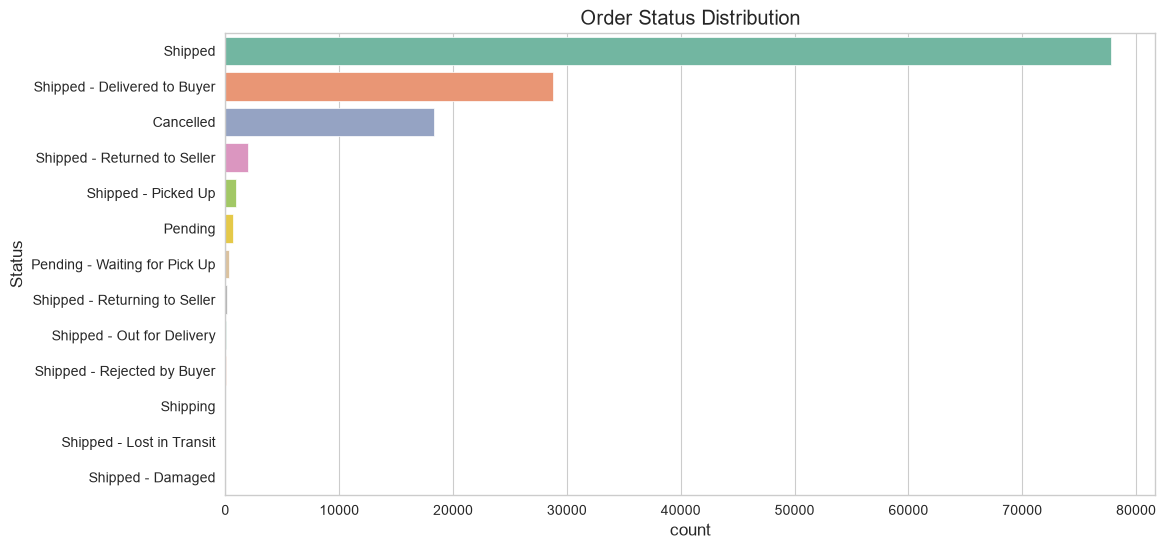

In [57]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=transaction_df,
    y="Status",
    order=transaction_df["Status"].value_counts().index,
    palette="Set2"
)

plt.title("Order Status Distribution")

plt.show()

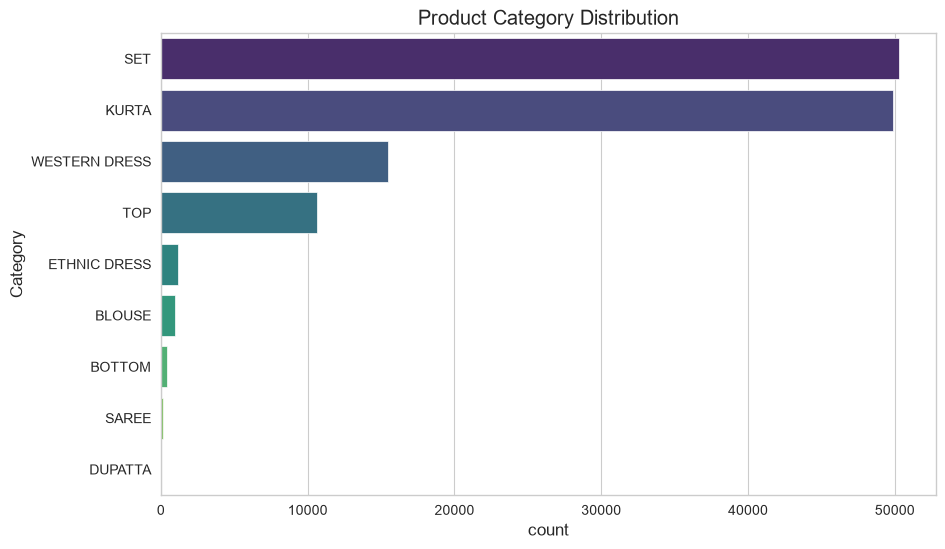

In [58]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=transaction_df,
    y="Category",
    order=transaction_df["Category"].value_counts().index,
    palette="viridis"
)

plt.title("Product Category Distribution")

plt.show()

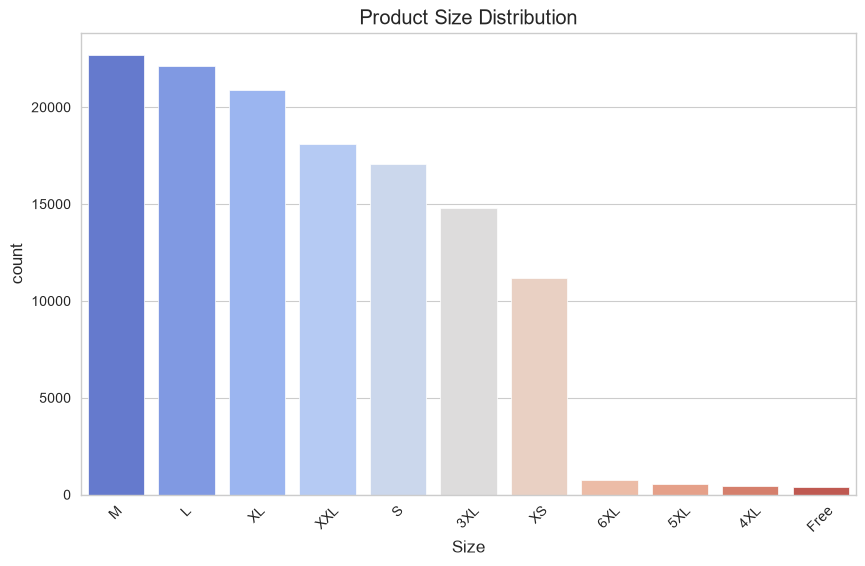

In [59]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=transaction_df,
    x="Size",
    order=transaction_df["Size"].value_counts().index,
    palette="coolwarm"
)

plt.xticks(rotation=45)

plt.title("Product Size Distribution")

plt.show()

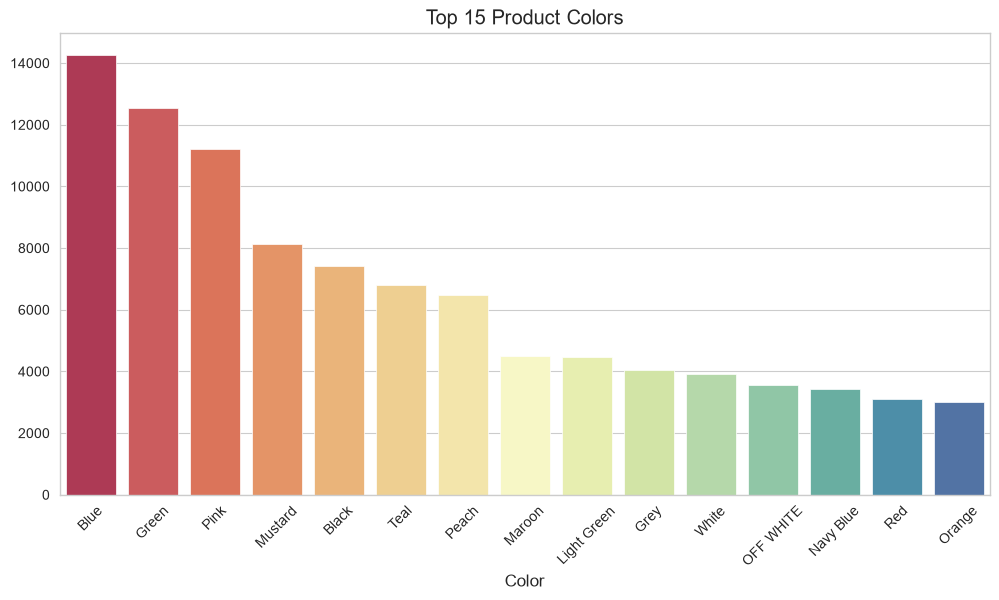

In [60]:
top_colors = (
    transaction_df["Color"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_colors.index,
    y=top_colors.values,
    palette="Spectral"
)

plt.xticks(rotation=45)

plt.title("Top 15 Product Colors")

plt.show()

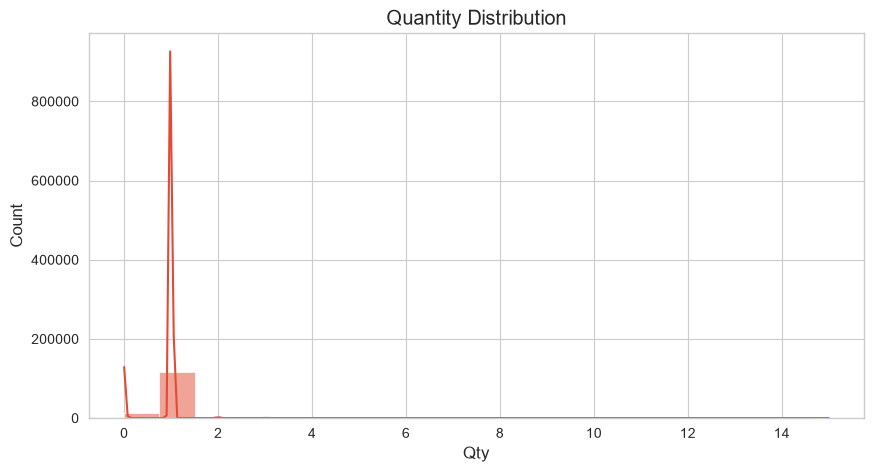

In [61]:
plt.figure(figsize=(10,5))

sns.histplot(
    transaction_df["Qty"],
    kde=True,
    bins=20
)

plt.title("Quantity Distribution")

plt.show()

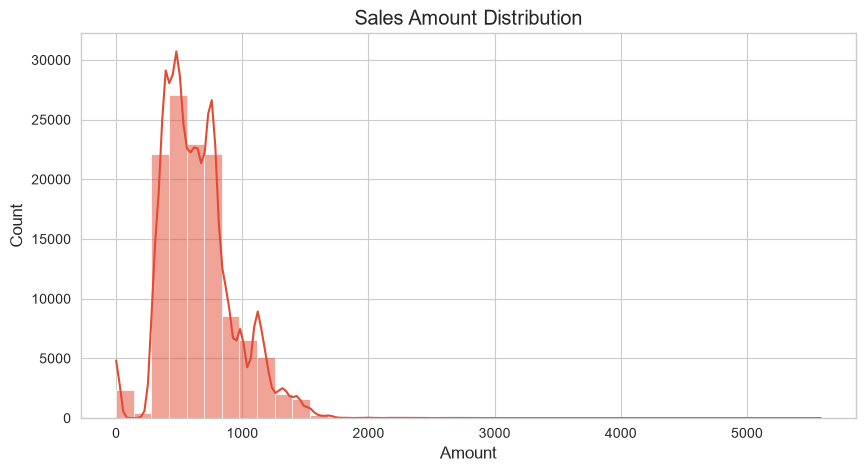

In [62]:
plt.figure(figsize=(10,5))

sns.histplot(
    transaction_df["Amount"],
    bins=40,
    kde=True
)

plt.title("Sales Amount Distribution")

plt.show()

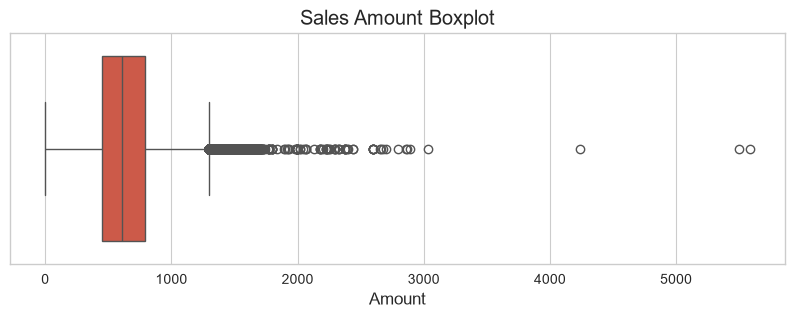

In [63]:
plt.figure(figsize=(10,3))

sns.boxplot(
    x=transaction_df["Amount"]
)

plt.title("Sales Amount Boxplot")

plt.show()

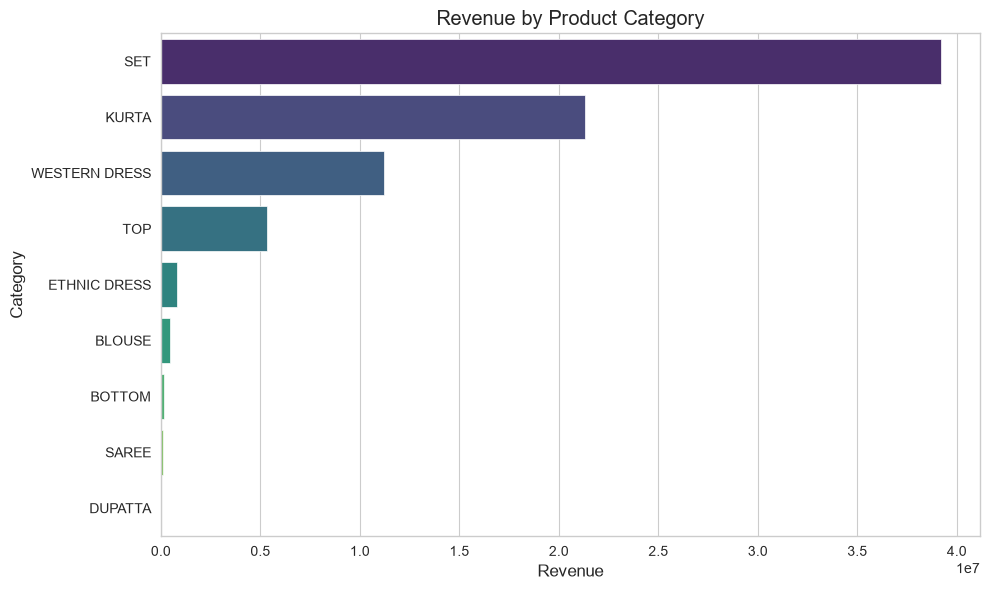

Category
SET              39204124.03
KURTA            21299546.70
WESTERN DRESS    11216072.69
TOP               5347792.30
ETHNIC DRESS       791217.66
BLOUSE             458408.18
BOTTOM             150667.98
SAREE              123933.76
DUPATTA               915.00
Name: Amount, dtype: float64

In [64]:
# ==========================================================
# Revenue by Product Category
# ==========================================================

category_revenue = (
    transaction_df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index,
    palette="viridis"
)

plt.title("Revenue by Product Category")
plt.xlabel("Revenue")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

category_revenue

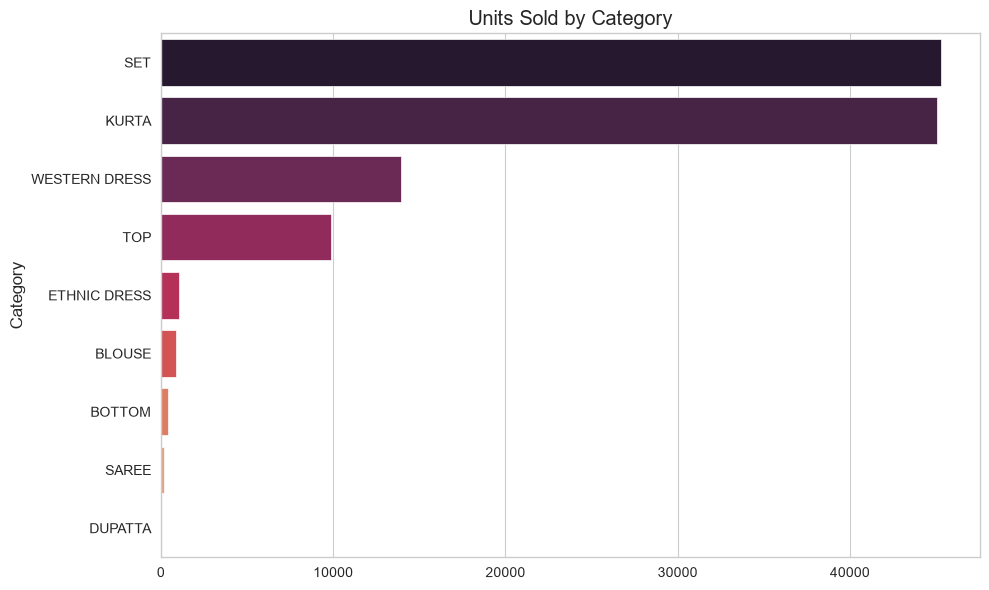

Category
SET              45289
KURTA            45045
WESTERN DRESS    13943
TOP               9903
ETHNIC DRESS      1053
BLOUSE             863
BOTTOM             398
SAREE              152
DUPATTA              3
Name: Qty, dtype: int64

In [65]:
category_qty = (
    transaction_df.groupby("Category")["Qty"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=category_qty.values,
    y=category_qty.index,
    palette="rocket"
)

plt.title("Units Sold by Category")

plt.tight_layout()
plt.show()

category_qty

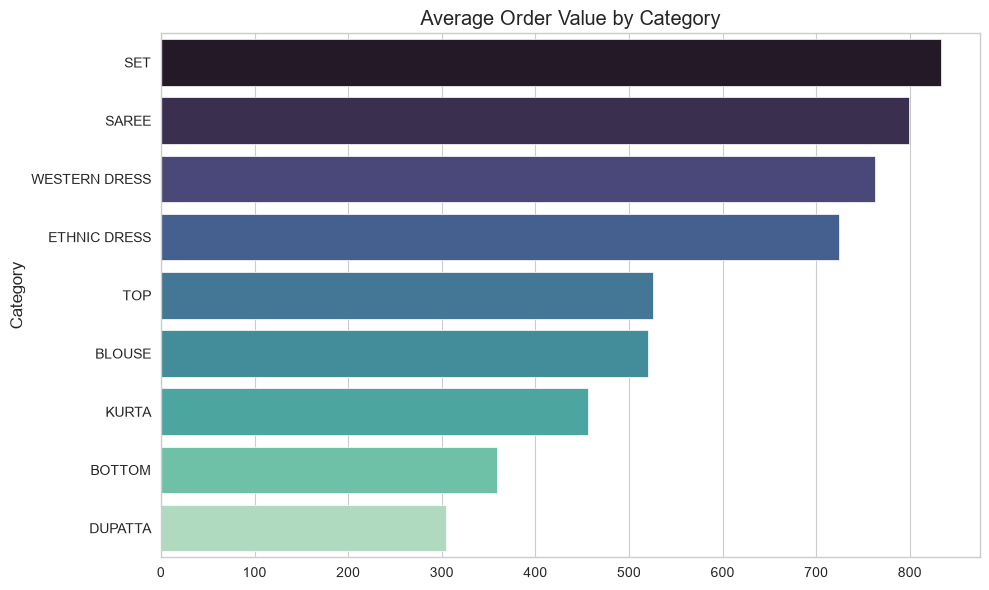

In [66]:
avg_order = (
    transaction_df.groupby("Category")["Amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=avg_order.values,
    y=avg_order.index,
    palette="mako"
)

plt.title("Average Order Value by Category")

plt.tight_layout()
plt.show()

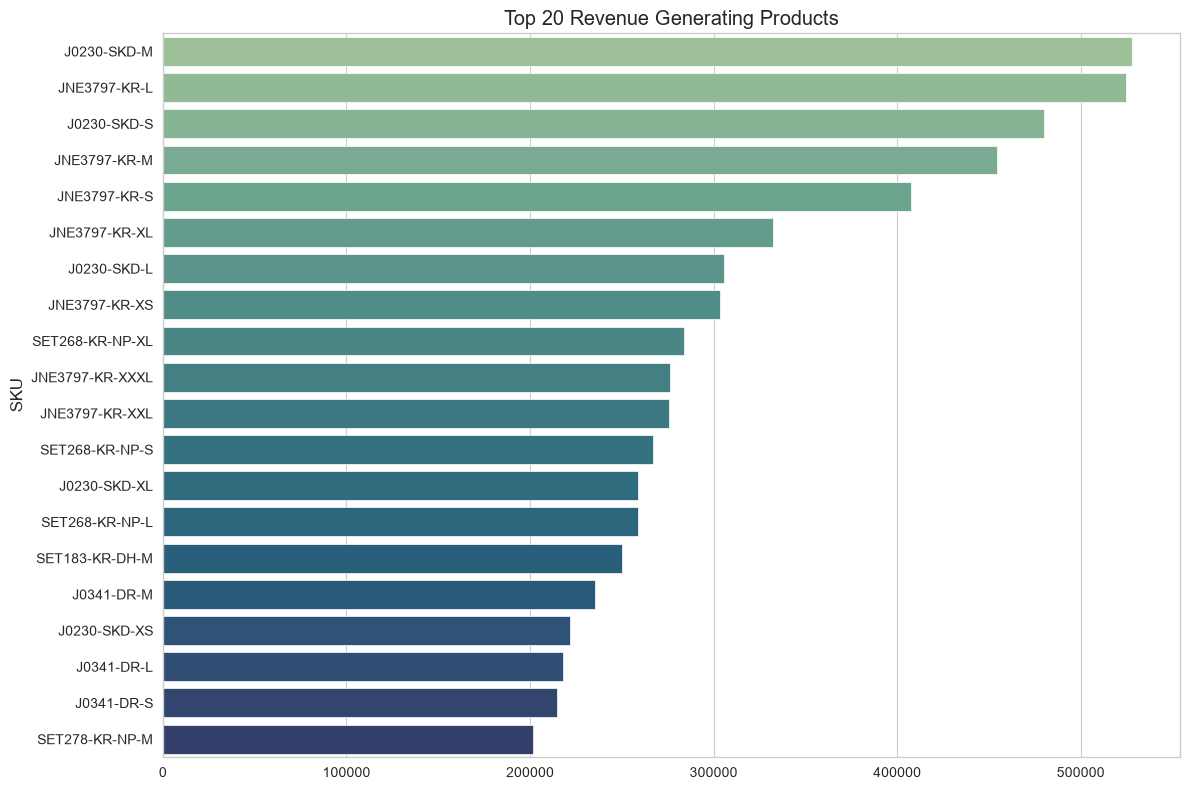

In [67]:
top_revenue_products = (
    transaction_df.groupby("SKU")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_revenue_products.values,
    y=top_revenue_products.index,
    palette="crest"
)

plt.title("Top 20 Revenue Generating Products")

plt.tight_layout()
plt.show()

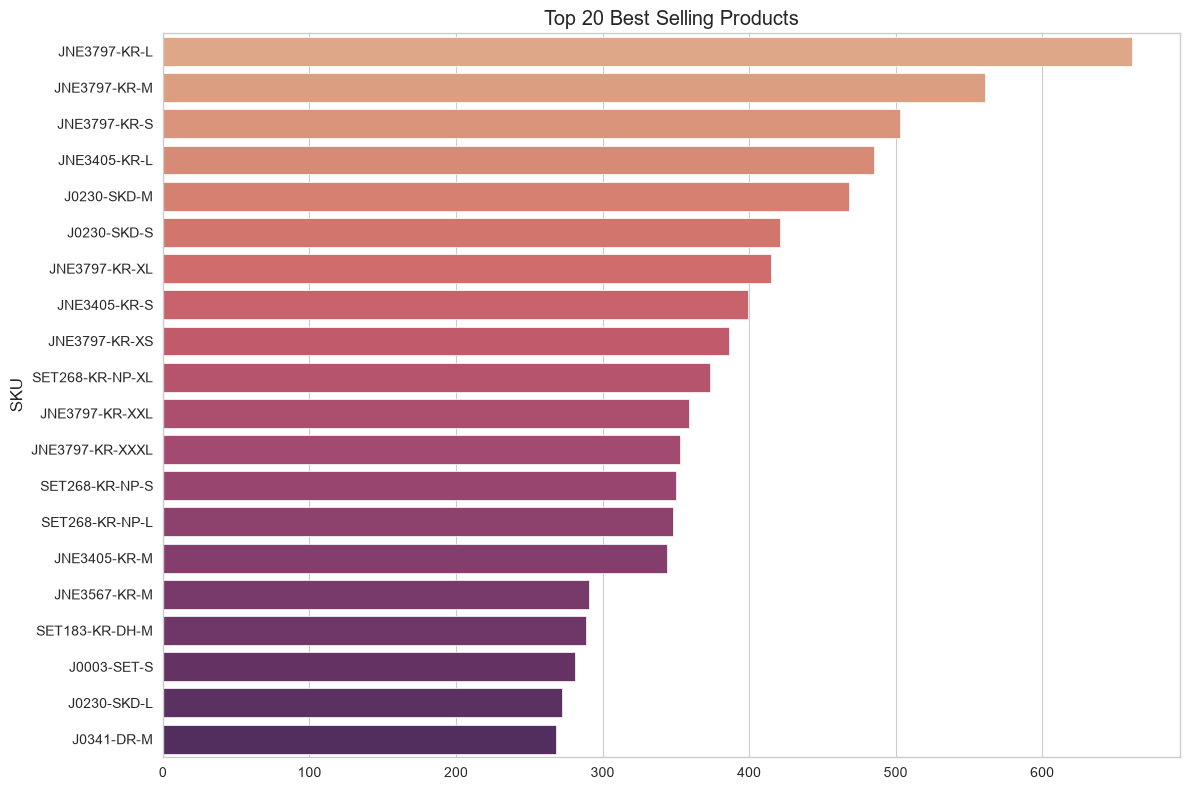

In [68]:
top_selling = (
    transaction_df.groupby("SKU")["Qty"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_selling.values,
    y=top_selling.index,
    palette="flare"
)

plt.title("Top 20 Best Selling Products")

plt.tight_layout()
plt.show()

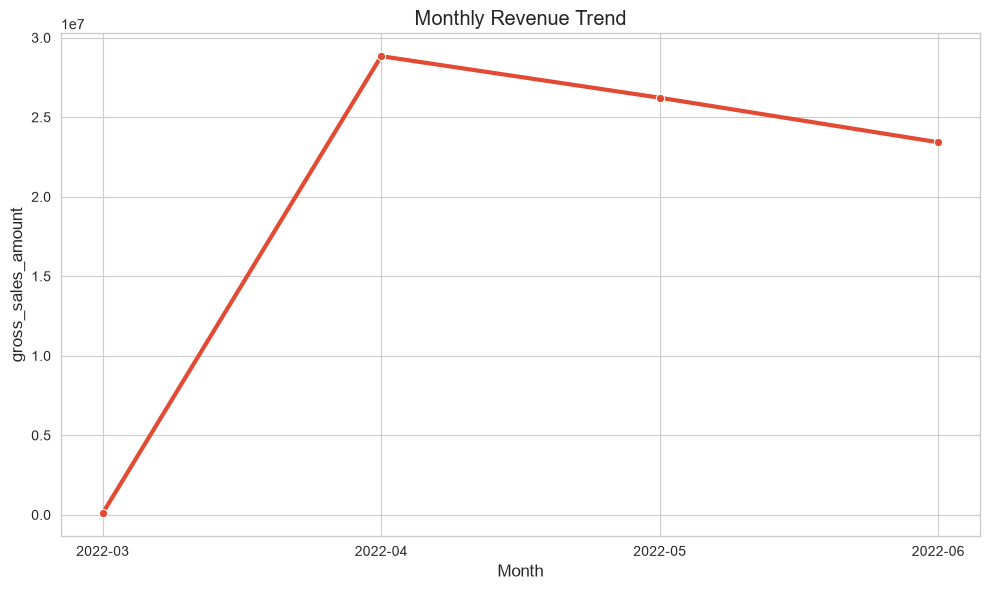

,Month,gross_sales_amount
0,2022-03,101683.85
1,2022-04,28838708.32
2,2022-05,26226476.75
3,2022-06,23425809.38


In [69]:
monthly_sales = (
    monthly_df.groupby("Month")["gross_sales_amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10,6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="gross_sales_amount",
    marker="o",
    linewidth=3
)

plt.title("Monthly Revenue Trend")

plt.tight_layout()
plt.show()

monthly_sales

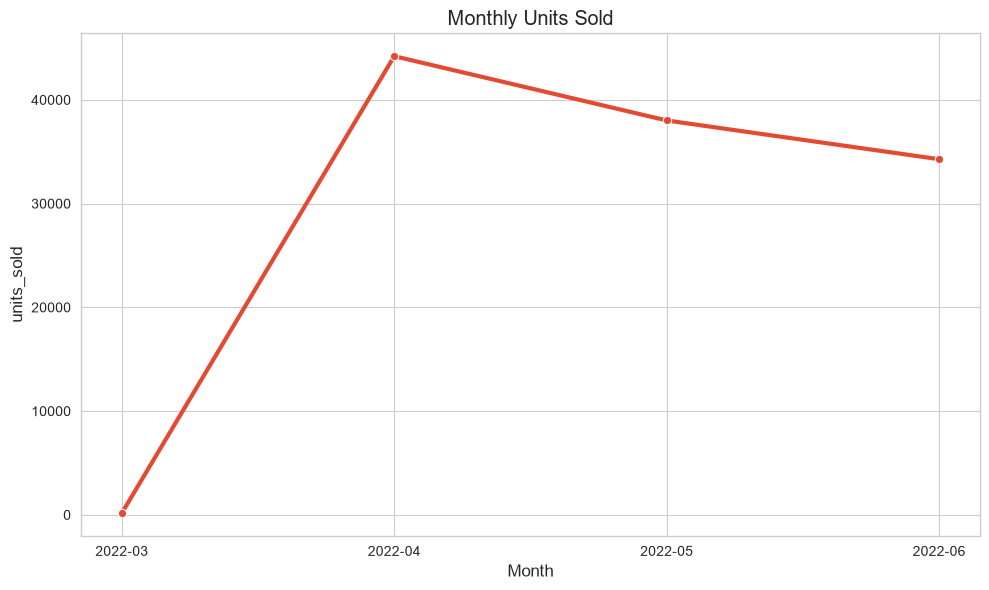

In [70]:
monthly_units = (
    monthly_df.groupby("Month")["units_sold"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10,6))

sns.lineplot(
    data=monthly_units,
    x="Month",
    y="units_sold",
    marker="o",
    linewidth=3
)

plt.title("Monthly Units Sold")

plt.tight_layout()
plt.show()

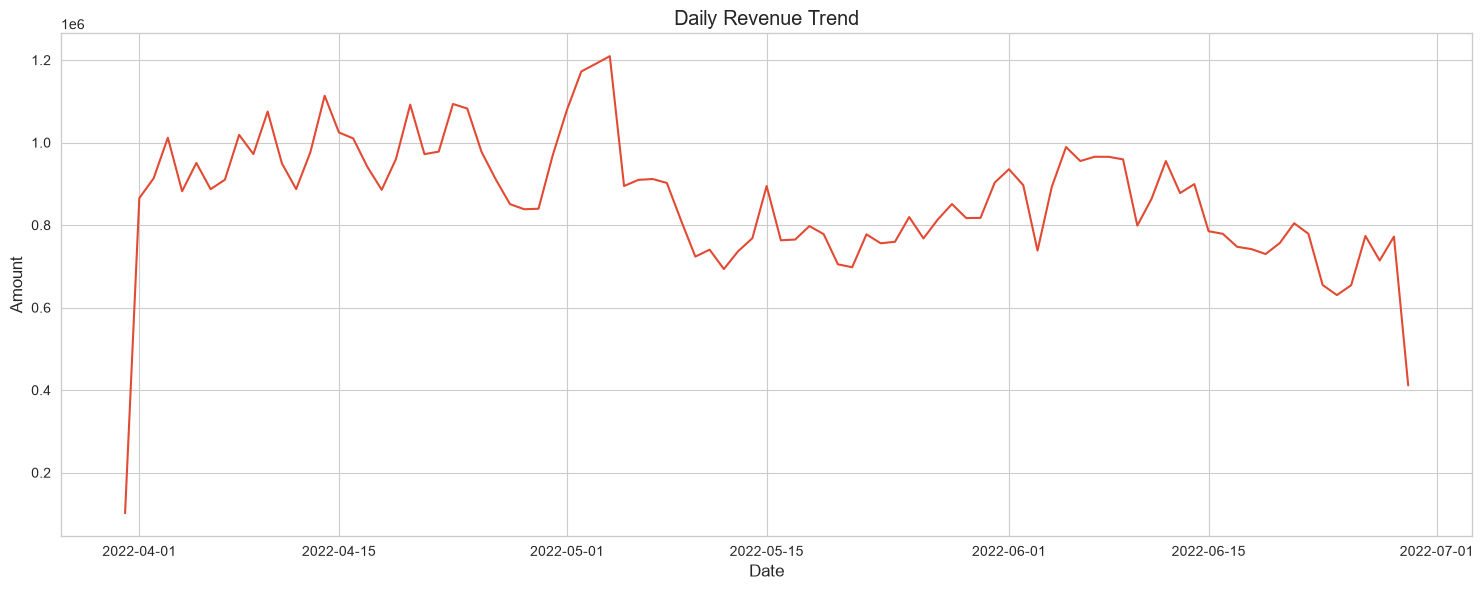

In [71]:
daily_sales = (
    transaction_df.groupby("Date")["Amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(15,6))

sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Amount"
)

plt.title("Daily Revenue Trend")

plt.tight_layout()
plt.show()

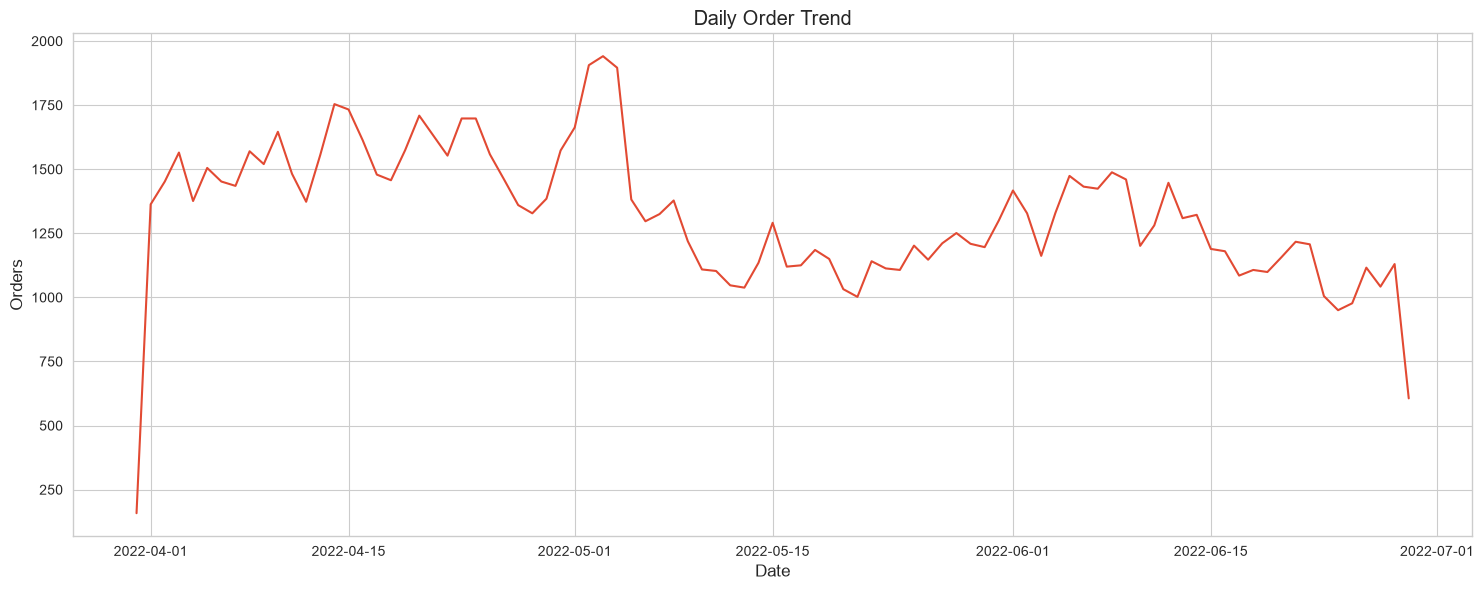

In [72]:
daily_orders = (
    transaction_df.groupby("Date")["Order ID"]
    .nunique()
    .reset_index(name="Orders")
)

plt.figure(figsize=(15,6))

sns.lineplot(
    data=daily_orders,
    x="Date",
    y="Orders"
)

plt.title("Daily Order Trend")

plt.tight_layout()
plt.show()

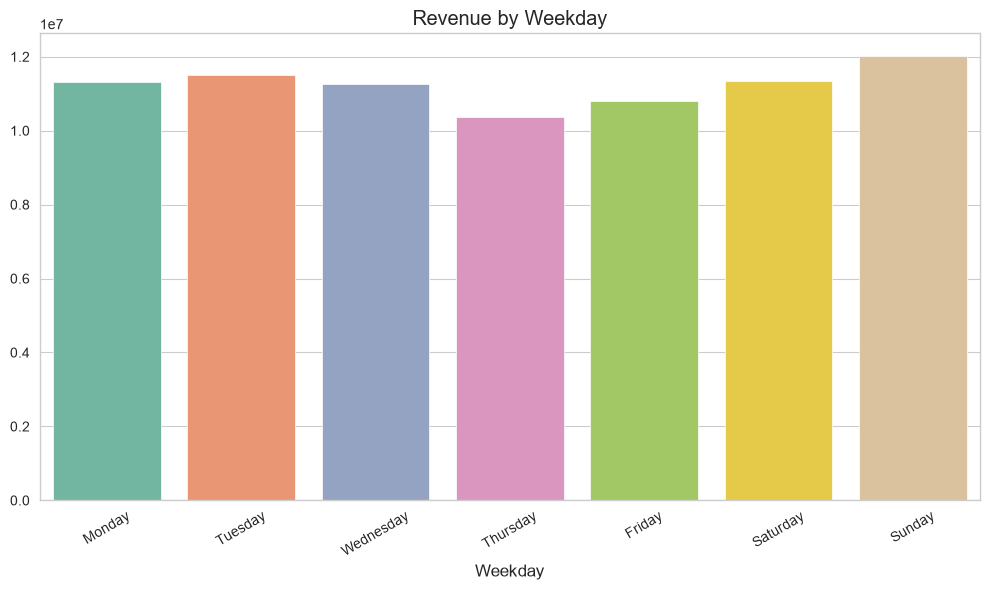

In [73]:
transaction_df["Weekday"] = transaction_df["Date"].dt.day_name()

weekday_sales = (
    transaction_df.groupby("Weekday")["Amount"]
    .sum()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values,
    palette="Set2"
)

plt.xticks(rotation=30)

plt.title("Revenue by Weekday")

plt.tight_layout()
plt.show()

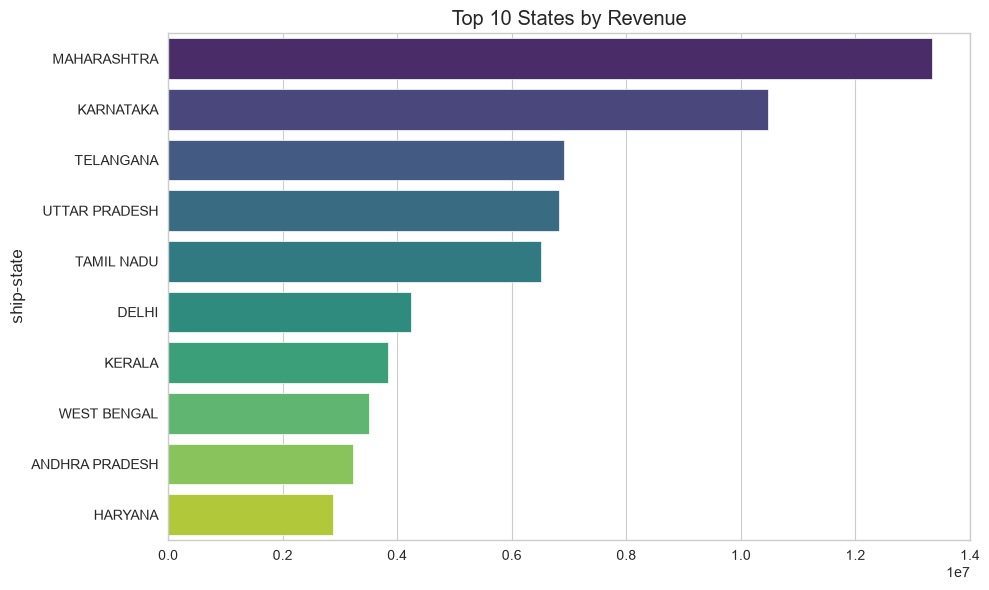

In [74]:
top_states = (
    transaction_df.groupby("ship-state")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_states.values,
    y=top_states.index,
    palette="viridis"
)

plt.title("Top 10 States by Revenue")

plt.tight_layout()
plt.show()

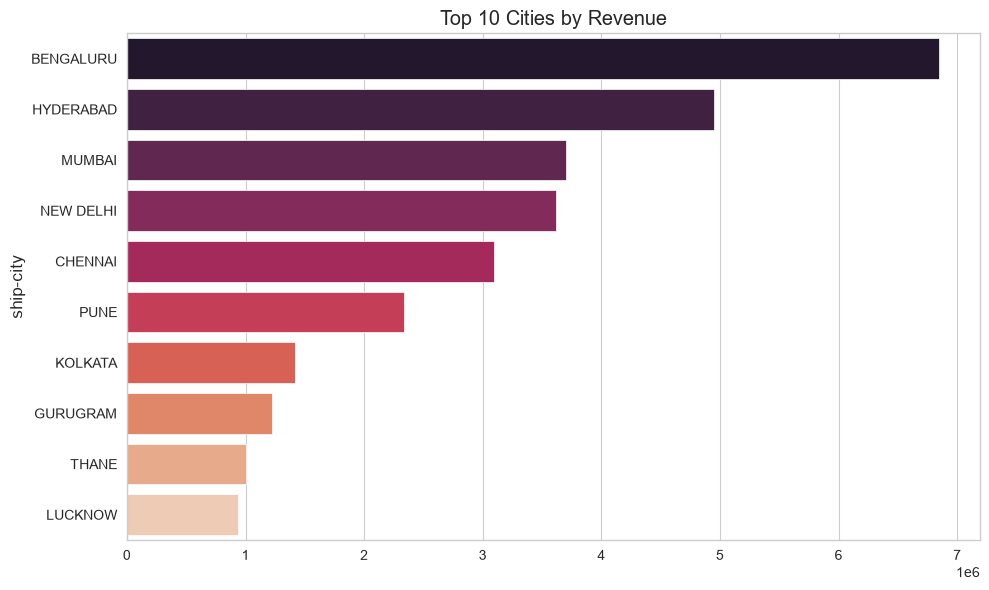

In [75]:
top_cities = (
    transaction_df.groupby("ship-city")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_cities.values,
    y=top_cities.index,
    palette="rocket"
)

plt.title("Top 10 Cities by Revenue")

plt.tight_layout()
plt.show()

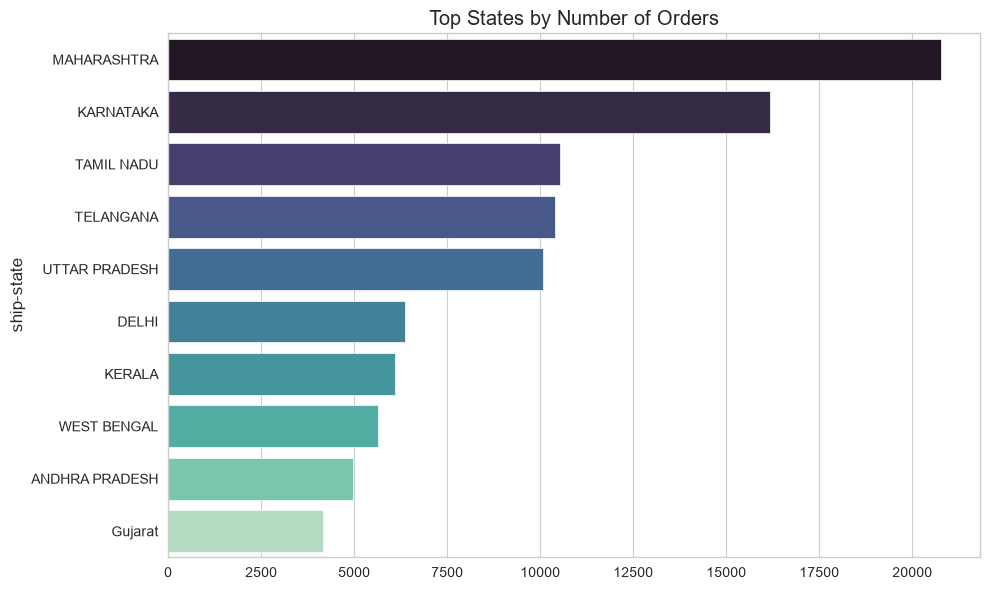

In [76]:
state_orders = (
    transaction_df.groupby("ship-state")["Order ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=state_orders.values,
    y=state_orders.index,
    palette="mako"
)

plt.title("Top States by Number of Orders")

plt.tight_layout()
plt.show()

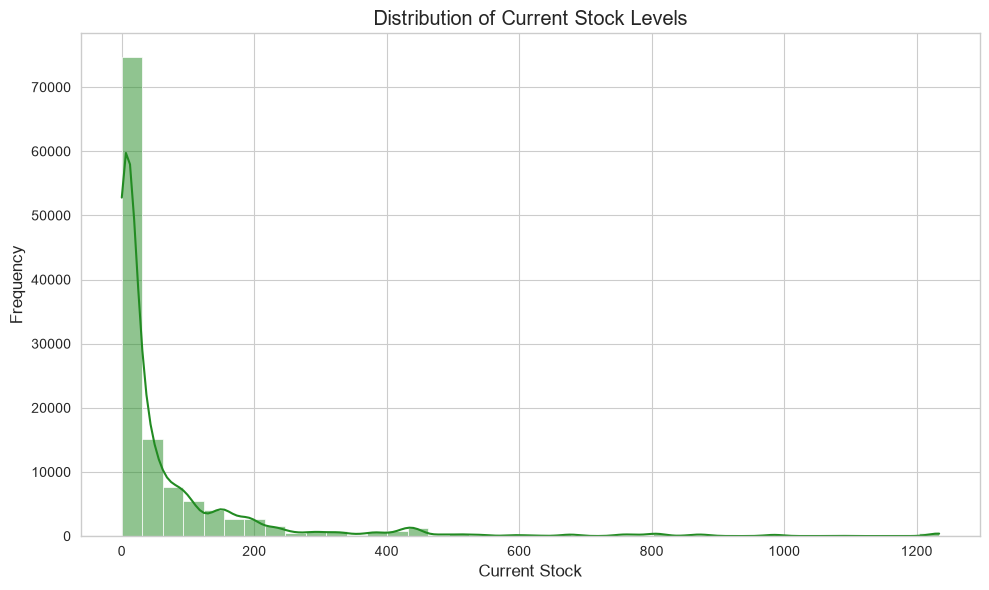

In [77]:
# ==========================================================
# Distribution of Current Stock
# ==========================================================

plt.figure(figsize=(10,6))

sns.histplot(
    transaction_df["Stock"].dropna(),
    bins=40,
    kde=True,
    color="forestgreen"
)

plt.title("Distribution of Current Stock Levels")
plt.xlabel("Current Stock")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

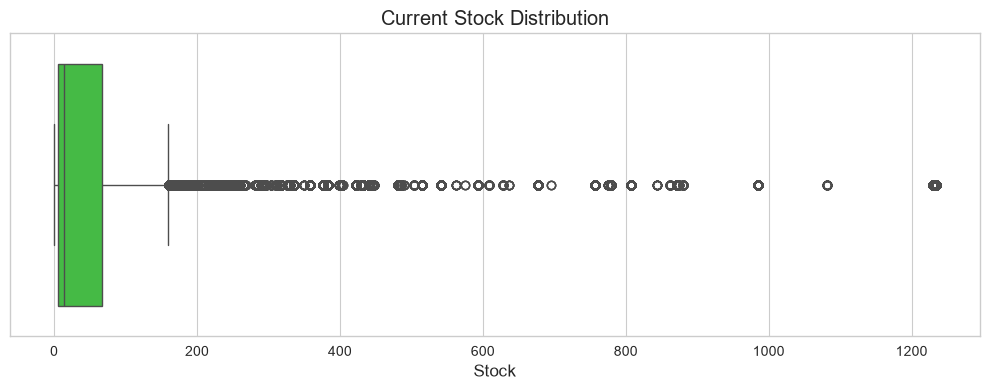

In [78]:
plt.figure(figsize=(10,4))

sns.boxplot(
    x=transaction_df["Stock"],
    color="limegreen"
)

plt.title("Current Stock Distribution")

plt.tight_layout()
plt.show()

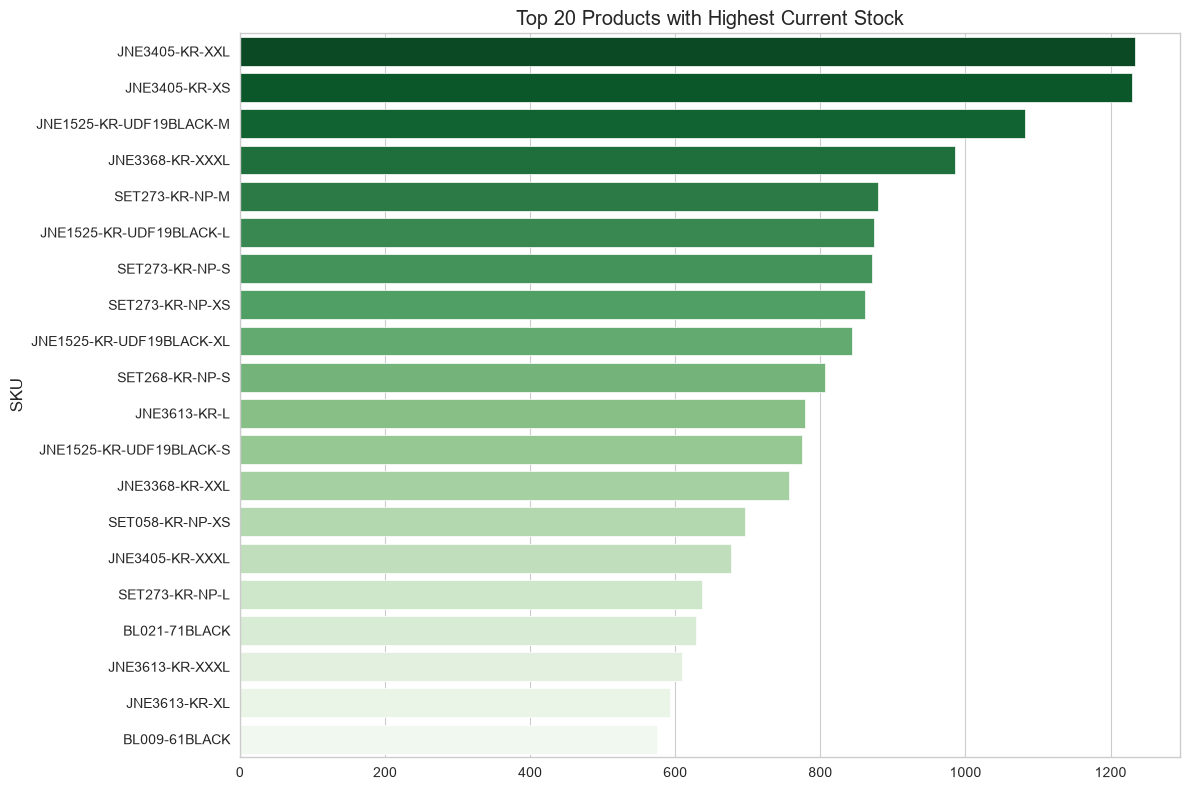

In [79]:
top_stock = (
    transaction_df.groupby("SKU")["Stock"]
    .max()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_stock.values,
    y=top_stock.index,
    palette="Greens_r"
)

plt.title("Top 20 Products with Highest Current Stock")

plt.tight_layout()
plt.show()

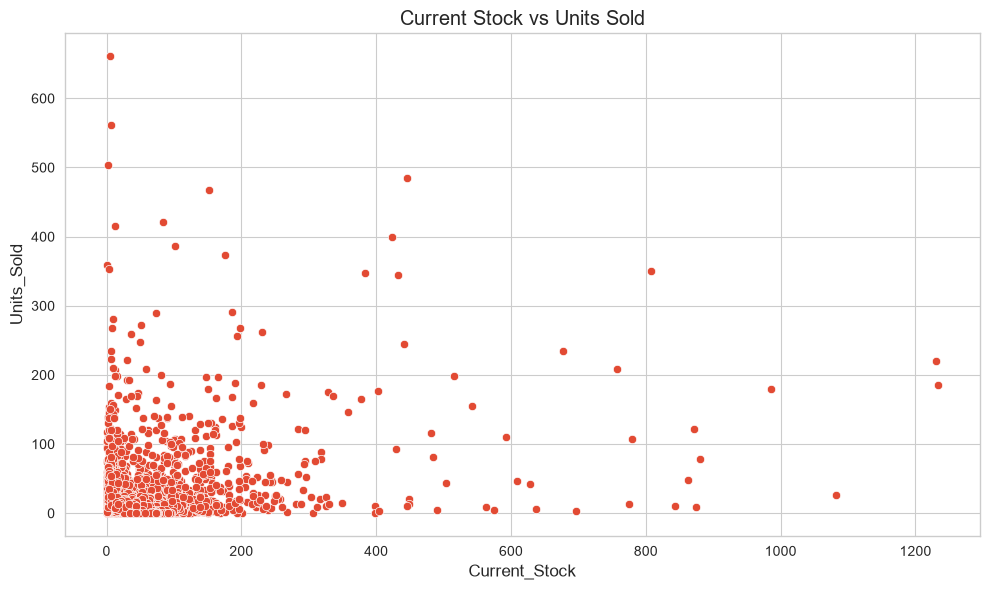

In [80]:
stock_sales = (
    transaction_df.groupby("SKU")
    .agg(
        Current_Stock=("Stock","max"),
        Units_Sold=("Qty","sum")
    )
    .reset_index()
)

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=stock_sales,
    x="Current_Stock",
    y="Units_Sold"
)

plt.title("Current Stock vs Units Sold")

plt.tight_layout()
plt.show()

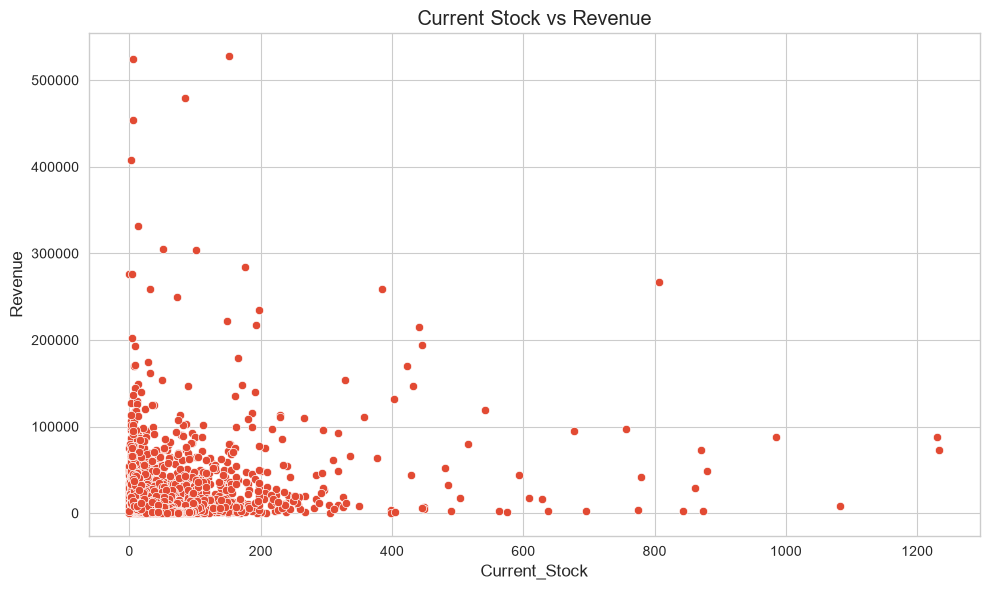

In [81]:
stock_revenue = (
    transaction_df.groupby("SKU")
    .agg(
        Current_Stock=("Stock","max"),
        Revenue=("Amount","sum")
    )
    .reset_index()
)

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=stock_revenue,
    x="Current_Stock",
    y="Revenue"
)

plt.title("Current Stock vs Revenue")

plt.tight_layout()
plt.show()

In [82]:
sales_efficiency = (
    transaction_df.groupby("SKU")
    .agg(
        Revenue=("Amount","sum"),
        Units=("Qty","sum")
    )
    .reset_index()
)

sales_efficiency["Sales_Efficiency"] = (
    sales_efficiency["Revenue"] /
    sales_efficiency["Units"]
)

sales_efficiency.head()

,SKU,Revenue,Units,Sales_Efficiency
0,AN201-RED-M,458.0,2,229.00
1,AN201-RED-XL,602.0,2,301.00
2,AN201-RED-XXL,229.0,1,229.00
3,AN202-ORANGE-M,530.0,2,265.00
4,AN202-ORANGE-S,1141.0,4,285.25


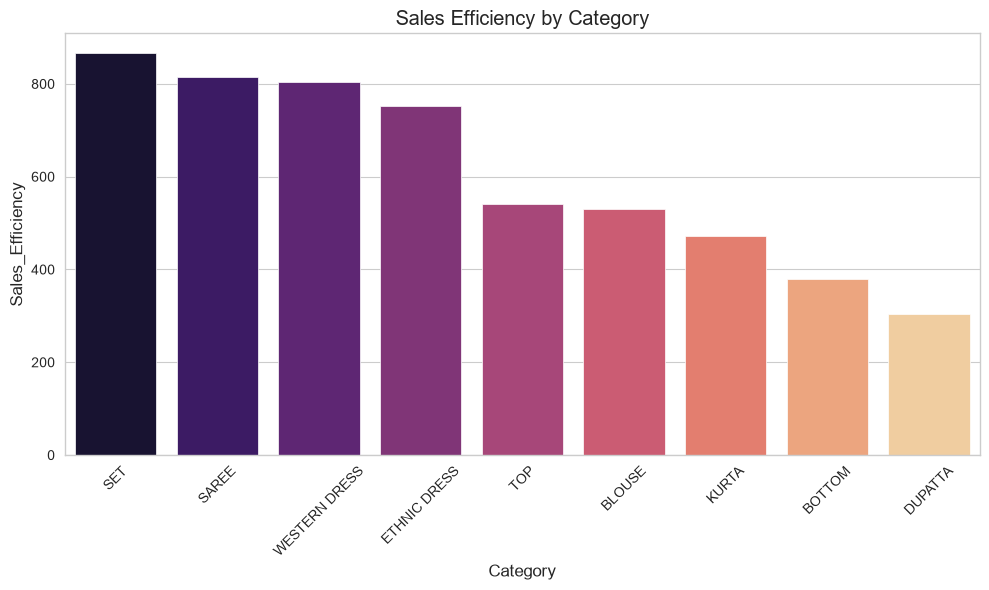

In [84]:
category_efficiency = (
    transaction_df.groupby("Category")
    .agg(
        Revenue=("Amount","sum"),
        Units=("Qty","sum")
    )
)

category_efficiency["Sales_Efficiency"] = (
    category_efficiency["Revenue"] /
    category_efficiency["Units"]
)

category_efficiency = category_efficiency.sort_values(
    "Sales_Efficiency",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=category_efficiency.index,
    y=category_efficiency["Sales_Efficiency"],
    palette="magma"
)

plt.xticks(rotation=45)

plt.title("Sales Efficiency by Category")

plt.tight_layout()
plt.show()

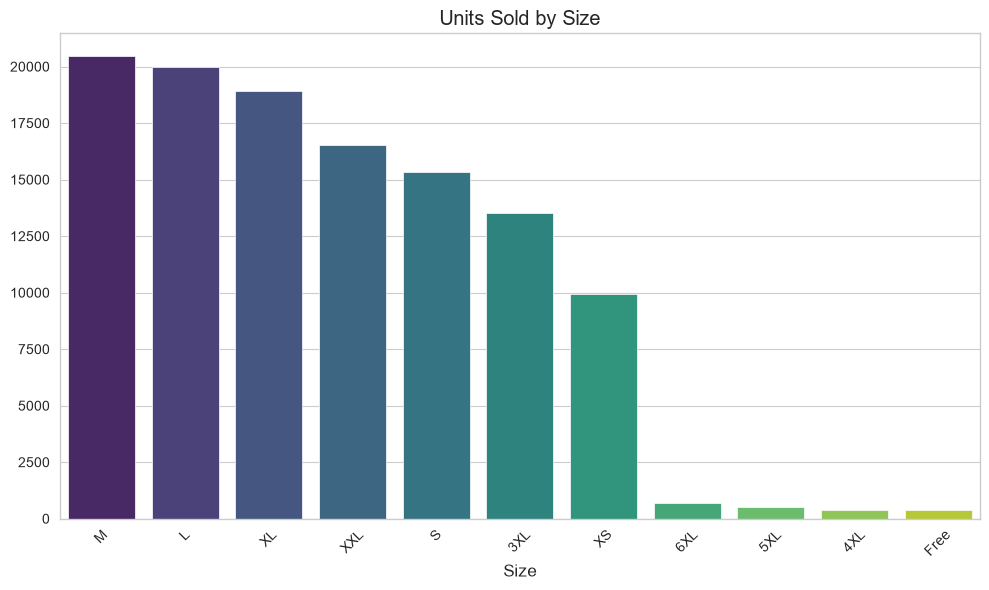

In [85]:
size_sales = (
    transaction_df.groupby("Size")["Qty"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=size_sales.index,
    y=size_sales.values,
    palette="viridis"
)

plt.xticks(rotation=45)

plt.title("Units Sold by Size")

plt.tight_layout()
plt.show()

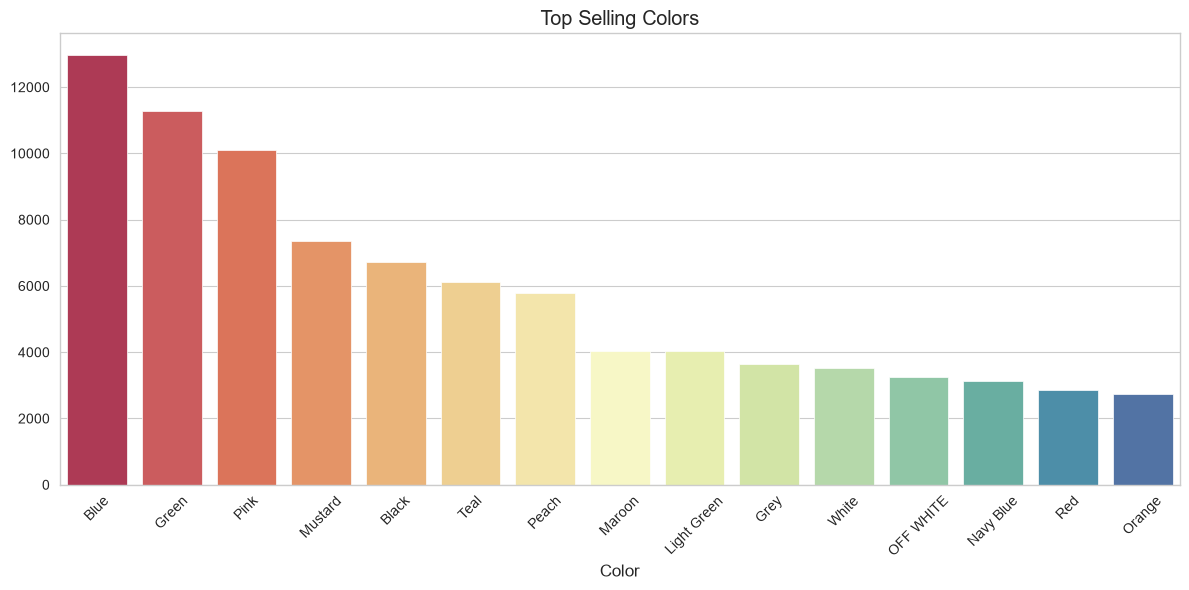

In [86]:
color_sales = (
    transaction_df.groupby("Color")["Qty"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=color_sales.index,
    y=color_sales.values,
    palette="Spectral"
)

plt.xticks(rotation=45)

plt.title("Top Selling Colors")

plt.tight_layout()
plt.show()

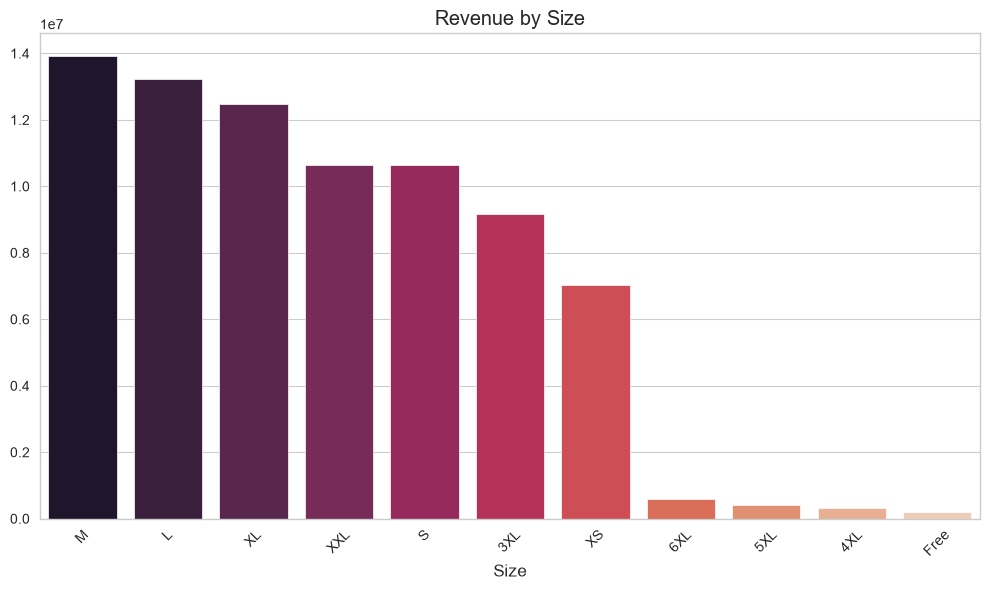

In [87]:
size_revenue = (
    transaction_df.groupby("Size")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=size_revenue.index,
    y=size_revenue.values,
    palette="rocket"
)

plt.xticks(rotation=45)

plt.title("Revenue by Size")

plt.tight_layout()
plt.show()

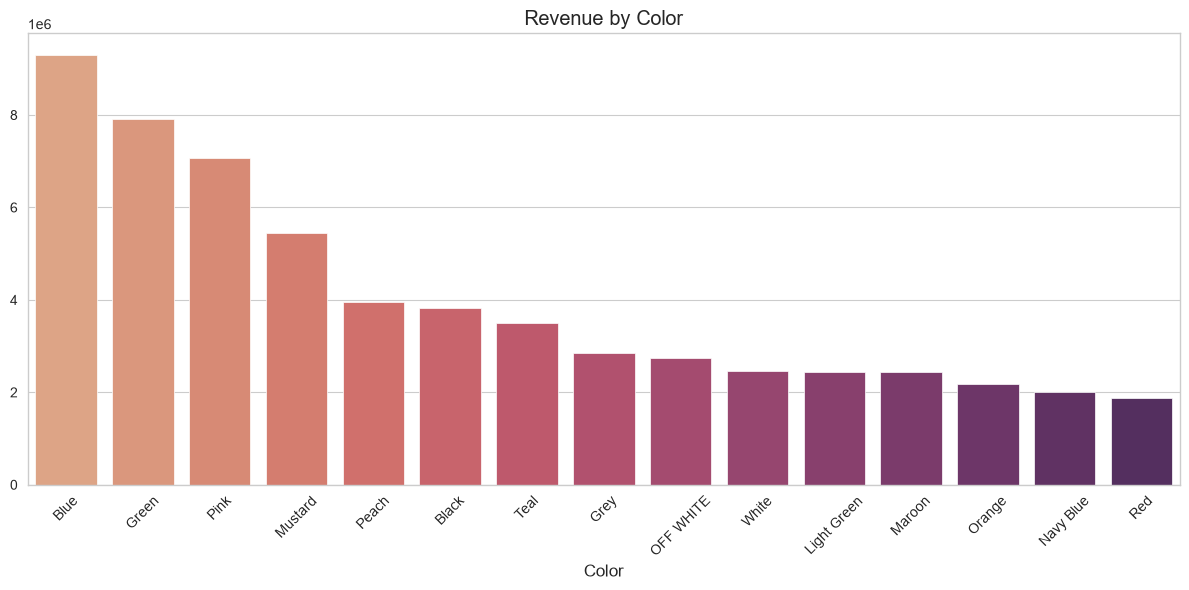

In [88]:
color_revenue = (
    transaction_df.groupby("Color")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=color_revenue.index,
    y=color_revenue.values,
    palette="flare"
)

plt.xticks(rotation=45)

plt.title("Revenue by Color")

plt.tight_layout()
plt.show()

In [89]:
inventory = (
    transaction_df.groupby("SKU")
    .agg(
        Current_Stock=("Stock","max"),
        Units_Sold=("Qty","sum")
    )
    .reset_index()
)

inventory["Stock_to_Sales_Ratio"] = (
    inventory["Current_Stock"] /
    inventory["Units_Sold"].replace(0,np.nan)
)

inventory.head()

,SKU,Current_Stock,Units_Sold,Stock_to_Sales_Ratio
0,AN201-RED-M,5.0,2,2.5
1,AN201-RED-XL,6.0,2,3.0
2,AN201-RED-XXL,3.0,1,3.0
3,AN202-ORANGE-M,3.0,2,1.5
4,AN202-ORANGE-S,16.0,4,4.0


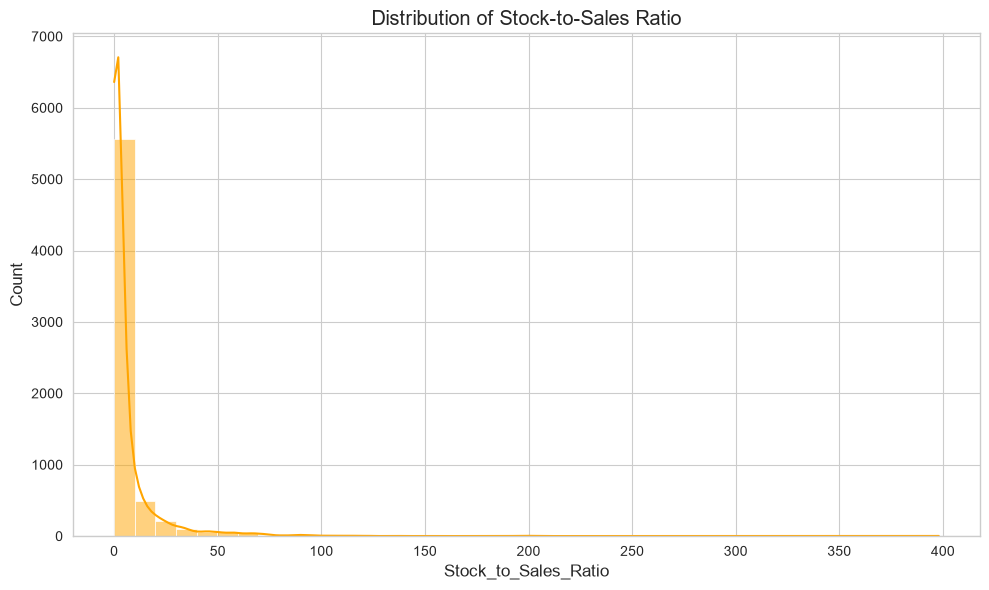

In [90]:
plt.figure(figsize=(10,6))

sns.histplot(
    inventory["Stock_to_Sales_Ratio"].dropna(),
    bins=40,
    kde=True,
    color="orange"
)

plt.title("Distribution of Stock-to-Sales Ratio")

plt.tight_layout()
plt.show()

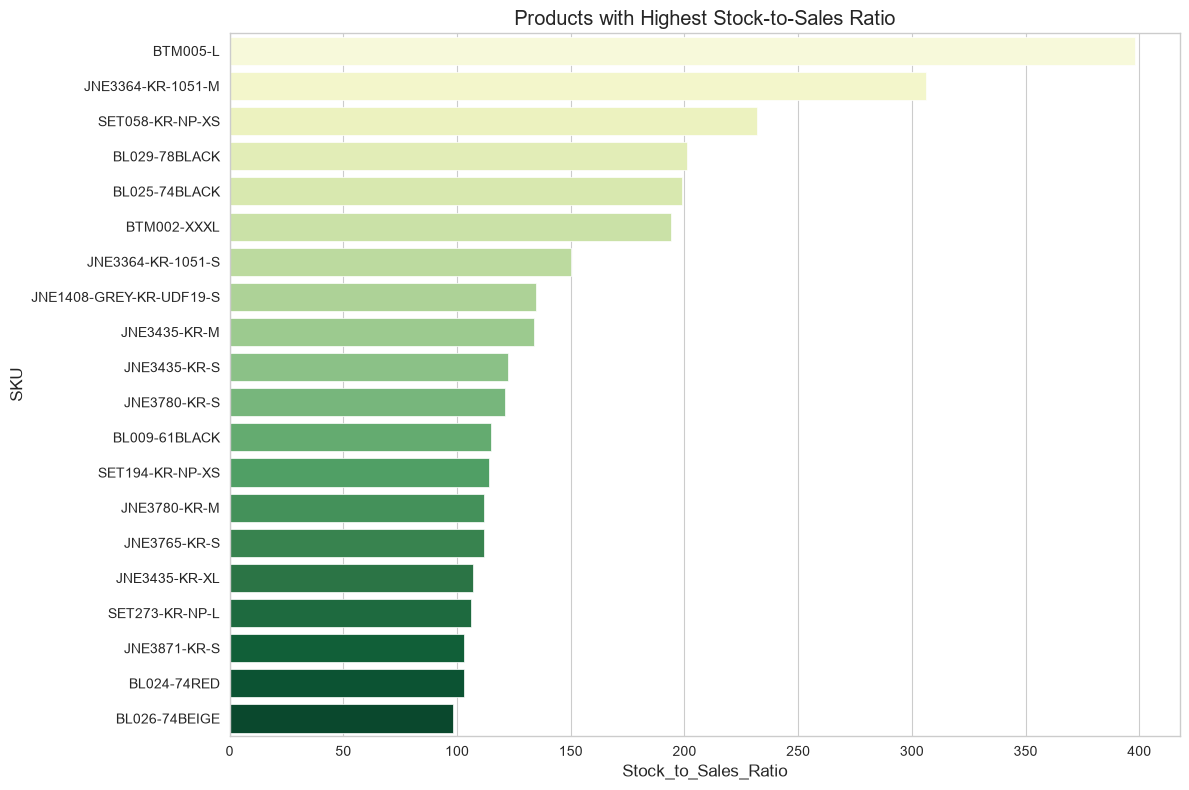

In [91]:
highest_ratio = (
    inventory.sort_values(
        "Stock_to_Sales_Ratio",
        ascending=False
    )
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    data=highest_ratio,
    x="Stock_to_Sales_Ratio",
    y="SKU",
    palette="YlGn"
)

plt.title("Products with Highest Stock-to-Sales Ratio")

plt.tight_layout()
plt.show()

In [92]:
# ==========================================================
# ABC Inventory Analysis
# ==========================================================

abc = (
    transaction_df.groupby("SKU")["Amount"]
    .sum()
    .reset_index()
)

abc = abc.sort_values("Amount", ascending=False)

abc["Revenue_Percentage"] = (
    abc["Amount"] / abc["Amount"].sum()
) * 100

abc["Cumulative_Percentage"] = abc["Revenue_Percentage"].cumsum()

def classify_abc(value):
    if value <= 80:
        return "A"
    elif value <= 95:
        return "B"
    else:
        return "C"

abc["ABC_Class"] = abc["Cumulative_Percentage"].apply(classify_abc)

abc.head()

,SKU,Amount,Revenue_Percentage,Cumulative_Percentage,ABC_Class
1346,J0230-SKD-M,527699.20,0.671436,0.671436,A
4548,JNE3797-KR-L,524581.77,0.667469,1.338905,A
1347,J0230-SKD-S,479937.14,0.610664,1.949569,A
4549,JNE3797-KR-M,454290.16,0.578031,2.527600,A
4550,JNE3797-KR-S,407302.57,0.518245,3.045845,A


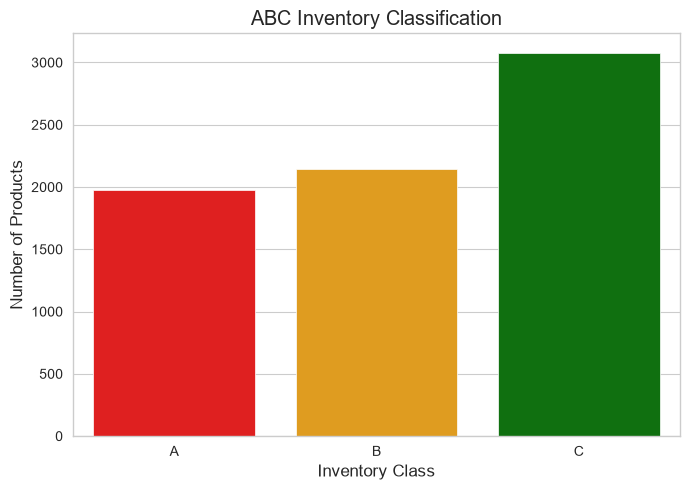

In [93]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=abc,
    x="ABC_Class",
    order=["A","B","C"],
    palette=["red","orange","green"]
)

plt.title("ABC Inventory Classification")
plt.xlabel("Inventory Class")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()


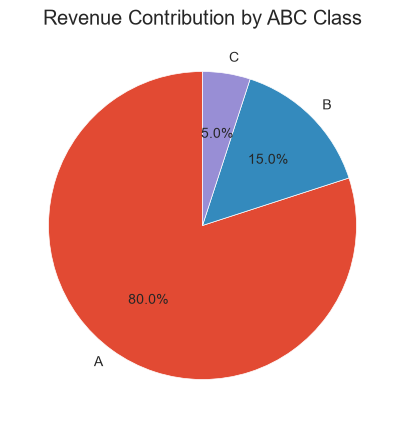

In [94]:
abc_revenue = (
    abc.groupby("ABC_Class")["Amount"]
    .sum()
    .reindex(["A","B","C"])
)

plt.figure(figsize=(7,5))

plt.pie(
    abc_revenue,
    labels=abc_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by ABC Class")

plt.show()

In [95]:
inventory = inventory.replace([np.inf,-np.inf], np.nan)

conditions = [
    inventory["Stock_to_Sales_Ratio"] < 1,
    inventory["Stock_to_Sales_Ratio"].between(1,5),
    inventory["Stock_to_Sales_Ratio"] > 5
]

choices = [
    "Low Stock",
    "Balanced",
    "Overstocked"
]

inventory["Inventory_Status"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

inventory.head()

,SKU,Current_Stock,Units_Sold,Stock_to_Sales_Ratio,Inventory_Status
0,AN201-RED-M,5.0,2,2.5,Balanced
1,AN201-RED-XL,6.0,2,3.0,Balanced
2,AN201-RED-XXL,3.0,1,3.0,Balanced
3,AN202-ORANGE-M,3.0,2,1.5,Balanced
4,AN202-ORANGE-S,16.0,4,4.0,Balanced


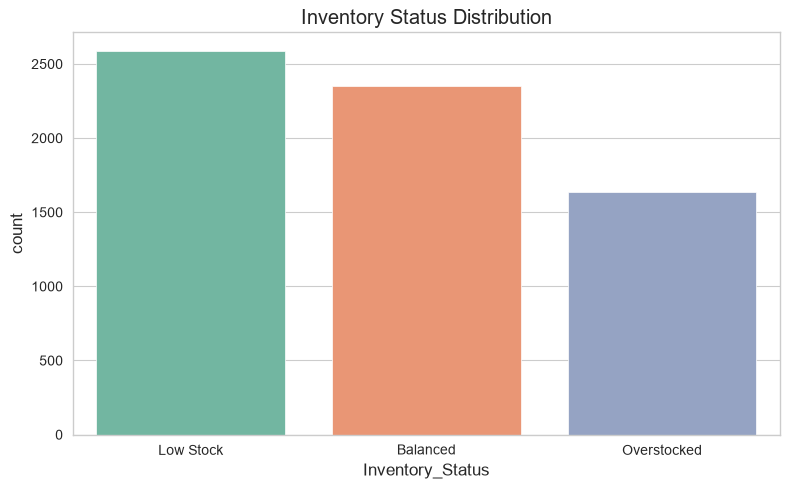

In [96]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=inventory,
    x="Inventory_Status",
    order=["Low Stock","Balanced","Overstocked"],
    palette="Set2"
)

plt.title("Inventory Status Distribution")

plt.tight_layout()
plt.show()

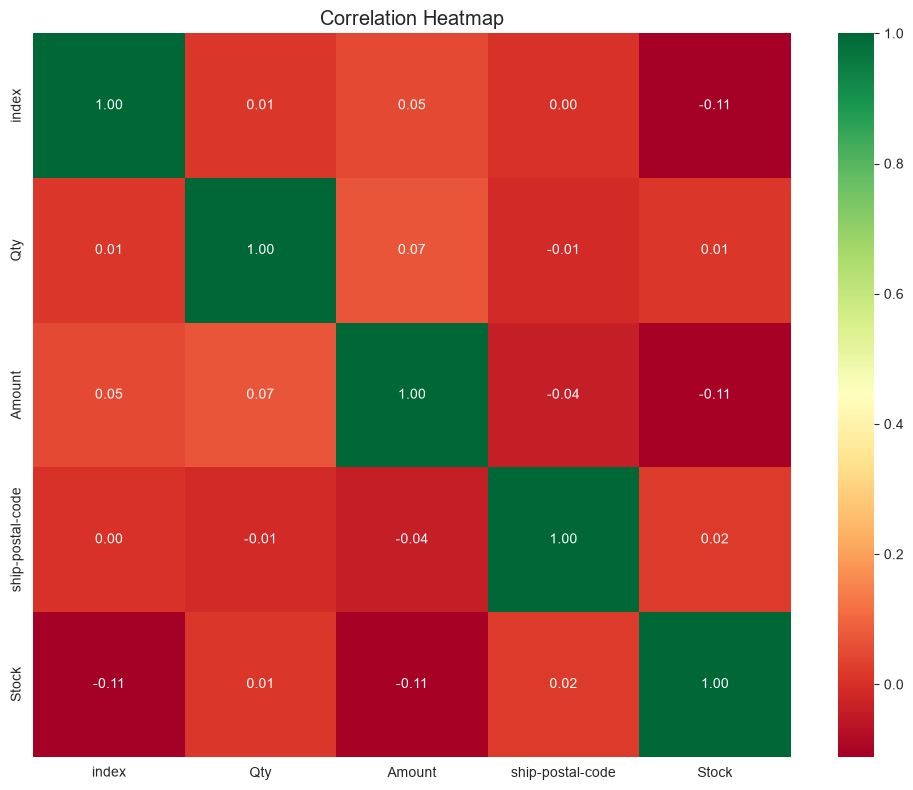

In [97]:
numeric = transaction_df.select_dtypes(include=np.number)

plt.figure(figsize=(10,8))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="RdYlGn",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

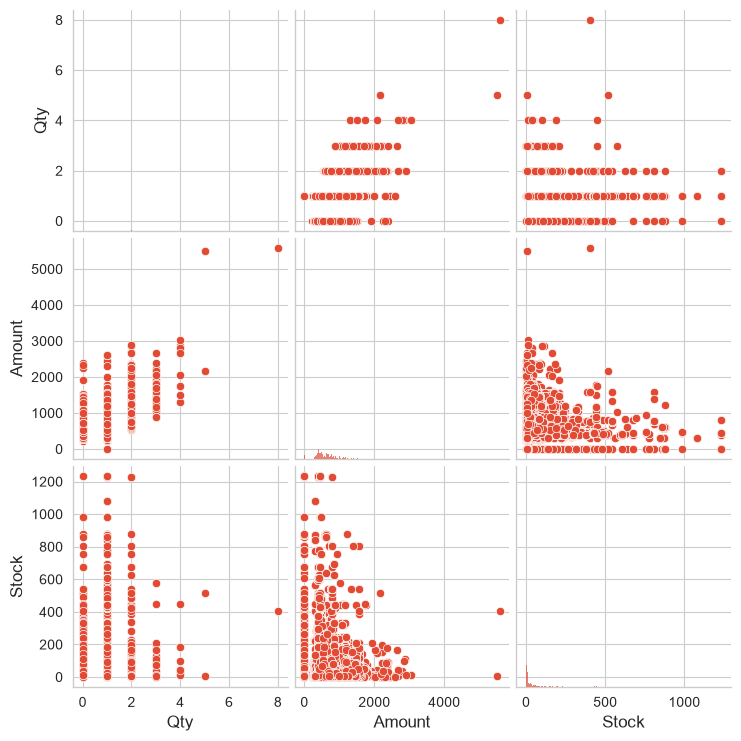

In [98]:
pair_data = transaction_df[
    ["Qty","Amount","Stock"]
].dropna()

sns.pairplot(pair_data)

plt.show()

In [99]:
correlation = stock_revenue["Current_Stock"].corr(
    stock_revenue["Revenue"]
)

print(f"Correlation between Stock and Revenue : {correlation:.3f}")

Correlation between Stock and Revenue : 0.216


In [100]:
correlation = stock_sales["Current_Stock"].corr(
    stock_sales["Units_Sold"]
)

print(f"Correlation between Stock and Units Sold : {correlation:.3f}")

Correlation between Stock and Units Sold : 0.301


In [101]:
fast = (
    inventory.sort_values(
        "Stock_to_Sales_Ratio"
    )
    .head(10)
)

fast

,SKU,Current_Stock,Units_Sold,Stock_to_Sales_Ratio,Inventory_Status
651,J0092-SET-S,0.0,2,0.0,Low Stock
5747,SET121-KR-NP-XS,0.0,2,0.0,Low Stock
5746,SET121-KR-NP-L,0.0,1,0.0,Low Stock
5740,SET116-KR-NP-M,0.0,6,0.0,Low Stock
3613,JNE3624-KR-L,0.0,3,0.0,Low Stock
6755,SET344-KR-NP-XXXL,0.0,30,0.0,Low Stock
3608,JNE3623-KR-L,0.0,3,0.0,Low Stock
4932,JNE3894-TP-XXXL,0.0,7,0.0,Low Stock
1680,J0328-KR-XL,0.0,3,0.0,Low Stock
1679,J0328-KR-S,0.0,2,0.0,Low Stock


In [102]:
slow = (
    inventory.sort_values(
        "Stock_to_Sales_Ratio",
        ascending=False
    )
    .head(10)
)

slow

,SKU,Current_Stock,Units_Sold,Stock_to_Sales_Ratio,Inventory_Status
186,BTM005-L,398.0,1,398.000000,Overstocked
2586,JNE3364-KR-1051-M,306.0,1,306.000000,Overstocked
5656,SET058-KR-NP-XS,696.0,3,232.000000,Overstocked
74,BL029-78BLACK,201.0,1,201.000000,Overstocked
70,BL025-74BLACK,199.0,1,199.000000,Overstocked
179,BTM002-XXXL,194.0,1,194.000000,Overstocked
2587,JNE3364-KR-1051-S,150.0,1,150.000000,Overstocked
2144,JNE1408-GREY-KR-UDF19-S,404.0,3,134.666667,Overstocked
2869,JNE3435-KR-M,268.0,2,134.000000,Overstocked
2870,JNE3435-KR-S,490.0,4,122.500000,Overstocked


In [103]:
kpi = pd.DataFrame({

    "Metric":[
        "Total Revenue",
        "Total Orders",
        "Unique Products",
        "Units Sold",
        "Categories",
        "States",
        "Cities"
    ],

    "Value":[

        transaction_df["Amount"].sum(),

        transaction_df["Order ID"].nunique(),

        transaction_df["SKU"].nunique(),

        transaction_df["Qty"].sum(),

        transaction_df["Category"].nunique(),

        transaction_df["ship-state"].nunique(),

        transaction_df["ship-city"].nunique()

    ]

})

kpi

,Metric,Value
0,Total Revenue,78592678.3
1,Total Orders,120378.0
2,Unique Products,7195.0
3,Units Sold,116649.0
4,Categories,9.0
5,States,69.0
6,Cities,8955.0


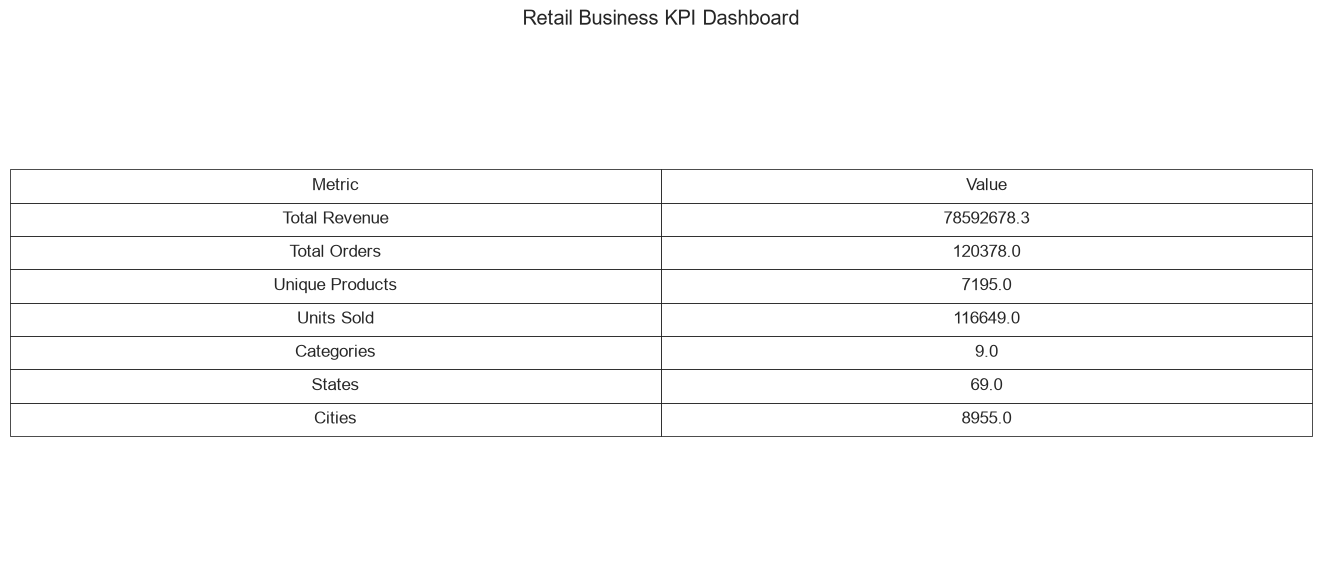

In [104]:
fig, ax = plt.subplots(figsize=(14,7))

ax.axis("off")

table = ax.table(
    cellText=kpi.values,
    colLabels=kpi.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2,2)

plt.title("Retail Business KPI Dashboard")

plt.show()

In [105]:
print("="*60)
print("KEY BUSINESS INSIGHTS")
print("="*60)

print("\n1. Product categories contribute differently to revenue and sales volume.")

print("\n2. Revenue is concentrated in a limited number of SKUs.")

print("\n3. Inventory levels are highly skewed, indicating possible overstocking for some products.")

print("\n4. Geographic demand varies significantly across states and cities.")

print("\n5. Several products exhibit low stock-to-sales ratios, suggesting potential stockout risks.")

print("\n6. ABC analysis identifies high-priority products that generate the majority of revenue.")

print("\n7. Correlation analysis provides insight into the relationship between inventory levels, sales volume, and revenue.")

print("\n8. These findings support the development of a machine learning model for demand forecasting and inventory optimization.")

KEY BUSINESS INSIGHTS

1. Product categories contribute differently to revenue and sales volume.

2. Revenue is concentrated in a limited number of SKUs.

3. Inventory levels are highly skewed, indicating possible overstocking for some products.

4. Geographic demand varies significantly across states and cities.

5. Several products exhibit low stock-to-sales ratios, suggesting potential stockout risks.

6. ABC analysis identifies high-priority products that generate the majority of revenue.

7. Correlation analysis provides insight into the relationship between inventory levels, sales volume, and revenue.

8. These findings support the development of a machine learning model for demand forecasting and inventory optimization.
